In [1]:
import numpy as np
import pandas as pd
import requests
import openmeteo_requests
from pprint import pprint
from pathlib import Path

In [3]:
dir_path = Path("./data/raw")
file_paths = list(dir_path.glob("*.csv"))
flight_data_separated = [pd.read_csv(file_path)[:-1] for file_path in file_paths]
flight_data_combined = pd.concat(flight_data_separated, ignore_index=True)
flight_data_combined.to_csv("./data/interim/ATL_combined.csv", index=False)

In [4]:
flight_data = pd.read_csv(r"data/interim/ATL_combined.csv")
flight_data["Date (MM/DD/YYYY)"] = pd.to_datetime(flight_data["Date (MM/DD/YYYY)"])
flight_data.rename(columns={"Date (MM/DD/YYYY)": "Date"}, inplace=True)
flight_data.head()

,Carrier Code,Date,Flight Number,Tail Number,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,UA,2025-01-01,213.0,N75432,EWR,08:00,08:00,130.0,127.0,0.0,08:21,21.0,0.0,0.0,0.0,0.0,0.0
1,UA,2025-01-01,235.0,N481UA,DEN,16:24,16:38,216.0,208.0,14.0,16:50,12.0,0.0,0.0,0.0,0.0,0.0
2,UA,2025-01-01,243.0,N27290,EWR,11:18,11:15,132.0,126.0,-3.0,11:41,26.0,0.0,0.0,0.0,0.0,0.0
3,UA,2025-01-01,340.0,N835UA,DEN,08:24,08:24,216.0,233.0,0.0,08:43,19.0,0.0,0.0,17.0,0.0,0.0
4,UA,2025-01-01,447.0,N68891,EWR,06:20,06:16,134.0,118.0,-4.0,06:33,17.0,0.0,0.0,0.0,0.0,0.0


## OpenMateo API Calls

API call

In [5]:
min_date = flight_data["Date"].min().strftime("%Y-%m-%d")
max_date = flight_data["Date"].max().strftime("%Y-%m-%d")

lat = 33.6367
lon = -84.4279
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
	"latitude": lat,
	"longitude": lon,
	"start_date": min_date,
	"end_date": max_date,
	"temperature_unit": "fahrenheit",
	"hourly": ["temperature_2m", "relative_humidity_2m", "dew_point_2m", "apparent_temperature", "precipitation", "rain", "snowfall", "cloud_cover", "windspeed_10m", "windgusts_10m", "winddirection_10m", "weathercode"],
}
weather = requests.get(url, params=params).json()

In [6]:
[value[0] for key, value in weather["hourly"].items()]

['2025-01-01T00:00',
 53.1,
 59,
 39.3,
 45.4,
 0.0,
 0.0,
 0.0,
 0,
 19.5,
 44.6,
 296,
 0]

JSON to CSV

In [10]:
weather_df = pd.DataFrame(weather["hourly"]).set_index("time")
weather_df.index = pd.to_datetime(weather_df.index)
weather_df.head()

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,windspeed_10m,windgusts_10m,winddirection_10m,weathercode
time,,,,,,,,,,,,
2025-01-01 00:00:00,53.1,59,39.3,45.4,0.0,0.0,0.0,0,19.5,44.6,296,0
2025-01-01 01:00:00,52.5,56,37.1,44.5,0.0,0.0,0.0,0,19.3,41.4,302,0
2025-01-01 02:00:00,50.3,60,36.8,42.1,0.0,0.0,0.0,0,19.4,41.0,303,0
2025-01-01 03:00:00,47.8,65,36.8,39.7,0.0,0.0,0.0,0,19.3,41.4,306,0
2025-01-01 04:00:00,46.1,69,36.5,38.2,0.0,0.0,0.0,1,18.6,41.0,310,0


Merging Data

In [8]:
flight_df = flight_data[["Carrier Code", "Date", "Flight Number", "Destination Airport", "Scheduled departure time", "Departure delay (Minutes)"]]
flight_df["Scheduled Departure Datetime"] = pd.to_datetime(flight_df["Date"].dt.strftime("%Y-%m-%d") + " " + flight_df["Scheduled departure time"])
flight_df["Scheduled Departure Hour"] = flight_df["Scheduled Departure Datetime"].dt.floor("h")

In [9]:
data = flight_df.merge(
    weather_df,
    left_on="Scheduled Departure Hour",
    right_on="time",
    how="left",
)
data.head()

,Carrier Code,Date,Flight Number,Destination Airport,Scheduled departure time,Departure delay (Minutes),Scheduled Departure Datetime,Scheduled Departure Hour,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,windspeed_10m,windgusts_10m,winddirection_10m,weathercode
0,UA,2025-01-01,213.0,EWR,08:00,0.0,2025-01-01 08:00:00,2025-01-01 08:00:00,44.0,68,34.1,36.2,0.0,0.0,0.0,0,16.2,39.6,314,0
1,UA,2025-01-01,235.0,DEN,16:24,14.0,2025-01-01 16:24:00,2025-01-01 16:00:00,45.5,63,33.6,36.5,0.0,0.0,0.0,68,20.6,49.3,327,2
2,UA,2025-01-01,243.0,EWR,11:18,-3.0,2025-01-01 11:18:00,2025-01-01 11:00:00,40.1,80,34.3,33.1,0.0,0.0,0.0,4,13.4,28.1,302,0
3,UA,2025-01-01,340.0,DEN,08:24,0.0,2025-01-01 08:24:00,2025-01-01 08:00:00,44.0,68,34.1,36.2,0.0,0.0,0.0,0,16.2,39.6,314,0
4,UA,2025-01-01,447.0,EWR,06:20,-4.0,2025-01-01 06:20:00,2025-01-01 06:00:00,44.4,69,34.9,36.1,0.0,0.0,0.0,100,18.9,39.6,312,3


In [9]:
data[data.duplicated()]

,Carrier Code,Date,Flight Number,Destination Airport,Scheduled departure time,Departure delay (Minutes),Scheduled Departure Datetime,Scheduled Departure Hour,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,snowfall,cloud_cover,windspeed_10m,windgusts_10m,winddirection_10m,weathercode
301129,UA,2025-01-01,213.0,EWR,08:00,0.0,2025-01-01 08:00:00,2025-01-01 08:00:00,44.0,68,34.1,36.2,0.0,0.0,0.0,0,16.2,39.6,314,0
301130,UA,2025-01-01,235.0,DEN,16:24,14.0,2025-01-01 16:24:00,2025-01-01 16:00:00,45.5,63,33.6,36.5,0.0,0.0,0.0,68,20.6,49.3,327,2
301131,UA,2025-01-01,243.0,EWR,11:18,-3.0,2025-01-01 11:18:00,2025-01-01 11:00:00,40.1,80,34.3,33.1,0.0,0.0,0.0,4,13.4,28.1,302,0
301132,UA,2025-01-01,340.0,DEN,08:24,0.0,2025-01-01 08:24:00,2025-01-01 08:00:00,44.0,68,34.1,36.2,0.0,0.0,0.0,0,16.2,39.6,314,0
301133,UA,2025-01-01,447.0,EWR,06:20,-4.0,2025-01-01 06:20:00,2025-01-01 06:00:00,44.4,69,34.9,36.1,0.0,0.0,0.0,100,18.9,39.6,312,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
602252,DL,2025-12-31,3196.0,SRQ,08:10,-4.0,2025-12-31 08:10:00,2025-12-31 08:00:00,29.7,54,14.9,20.2,0.0,0.0,0.0,0,13.9,28.4,307,0
602253,DL,2025-12-31,3198.0,PNS,10:00,-2.0,2025-12-31 10:00:00,2025-12-31 10:00:00,28.7,58,15.7,19.6,0.0,0.0,0.0,0,12.9,29.5,309,0
602254,DL,2025-12-31,8800.0,MSY,11:49,-9.0,2025-12-31 11:49:00,2025-12-31 11:00:00,28.0,59,15.5,19.2,0.0,0.0,0.0,0,12.0,26.3,307,0
602255,DL,2025-12-31,8801.0,MIA,12:00,-5.0,2025-12-31 12:00:00,2025-12-31 12:00:00,27.6,58,14.9,19.0,0.0,0.0,0.0,0,10.8,24.1,306,0


Analysis

<Axes: title={'center': 'Departure Delay vs Precipitation'}, xlabel='precipitation', ylabel='Departure delay (Minutes)'>

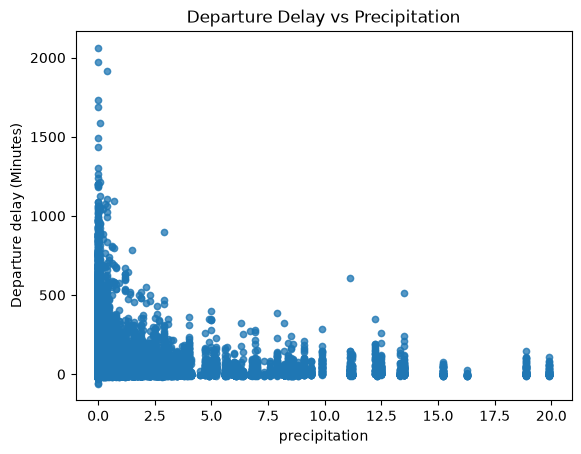

In [10]:
data.plot(x="precipitation", y="Departure delay (Minutes)", kind="scatter", alpha=0.5, title="Departure Delay vs Precipitation")

<Axes: title={'center': 'Departure Delay vs Scheduled Departure Hour'}, xlabel='Date'>

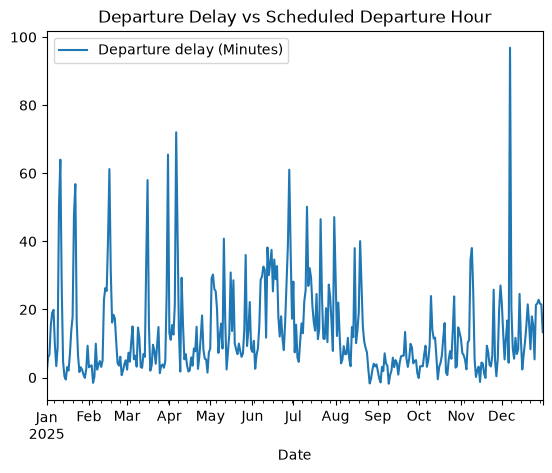

In [11]:
timeseries = data.groupby("Date")["Departure delay (Minutes)"].mean().reset_index()

timeseries.plot(x="Date", y="Departure delay (Minutes)", kind="line", title="Departure Delay vs Scheduled Departure Hour")

<Axes: title={'center': 'Distribution of Departure Delays'}, ylabel='Frequency'>

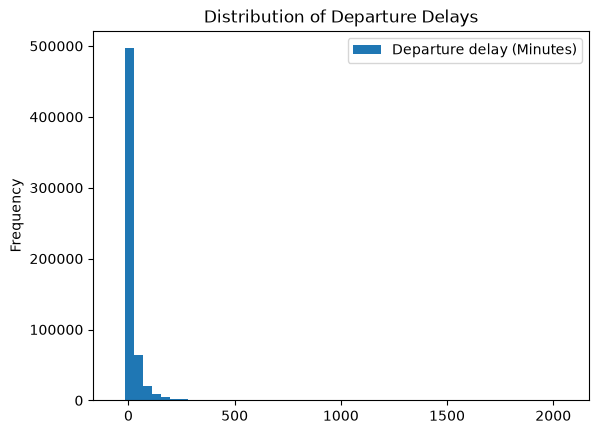

In [12]:
data.plot(kind="hist", y="Departure delay (Minutes)", bins=50, title="Distribution of Departure Delays")

In [13]:
data["Departure delay (Minutes)"].describe()

count    602257.000000
mean         13.615101
std          49.078026
min         -60.000000
25%          -5.000000
50%          -1.000000
75%          12.000000
max        2063.000000
Name: Departure delay (Minutes), dtype: float64